# Exploratory data analysis
Use all labeled applications for descriptive summaries. Percentages are in percentage points. Group rates describe this historical sample and do not establish cause. No data-dependent bin or statistic from this notebook enters the pipeline.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / "train.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
train = pd.read_csv(ROOT / "train.csv")

import matplotlib.pyplot as plt
import seaborn as sns
from src.feature_engineering import as_number

sns.set_theme(style="whitegrid", font_scale=0.9)
reports = ROOT / "reports"
figures = reports / "figures"
figures.mkdir(parents=True, exist_ok=True)
findings = []

def note(message):
    findings.append(message)
    display(Markdown(message))

def save(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + ".png"), dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)

data = train.copy()
percent_fields = ["interest_rate_pct", "revolving_utilization_pct"]
for col in percent_fields:
    data[col] = as_number(data[col], percent=True)
ids = ["application_id", "applicant_ref_id"]
target = "default_flag"
numbers = data.drop(columns=ids + [target]).select_dtypes("number").columns.tolist()
categories = data.select_dtypes("object").columns.tolist()
for col in categories:
    data[col] = data[col].str.strip()

## Missing data
Inspect every raw column in the table. The chart highlights fields with missing values. Count zeros as observed values.

,raw_dtype,missing_count,missing_percent,distinct_present
column,,,,
application_id,int64,0,0.000,31016
applicant_ref_id,float64,0,0.000,31016
requested_amount,float64,0,0.000,826
repayment_tenure,object,0,0.000,2
interest_rate_pct,object,0,0.000,367
monthly_emi,float64,0,0.000,13233
risk_tier,object,0,0.000,7
risk_subtier,object,0,0.000,35
employment_tenure,object,829,2.673,11


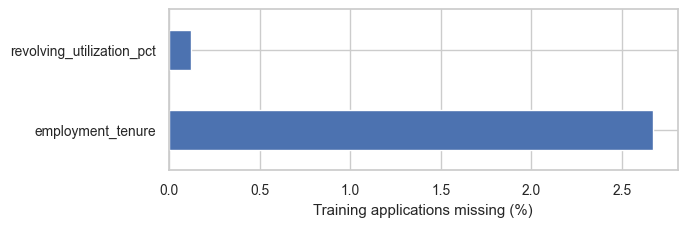

Missing training values: employment_tenure 829 (2.67%), revolving_utilization_pct 38 (0.12%). Preserve missing employment as a category and impute utilization using the training-fold median.

In [2]:
quality = pd.DataFrame({"raw_dtype": train.dtypes.astype(str), "missing_count": data.isna().sum(),
                        "missing_percent": data.isna().mean() * 100, "distinct_present": data.nunique()})
quality.index.name = "column"
quality.to_csv(reports / "data_quality_report.csv")
display(quality.round(3))
fig, ax = plt.subplots(figsize=(7, 2.4))
quality.loc[quality.missing_count > 0, "missing_percent"].plot.barh(ax=ax)
ax.set(xlabel="Training applications missing (%)", ylabel="")
save(fig, "missingness")
missing = quality[quality.missing_count > 0]
note("Missing training values: " + ", ".join(
    f"{name} {row.missing_count:,} ({row.missing_percent:.2f}%)" for name, row in missing.iterrows()
) + ". Preserve missing employment as a category and impute utilization using the training-fold median.")

## Target balance
Count the two observed loan outcomes before comparing default rates.

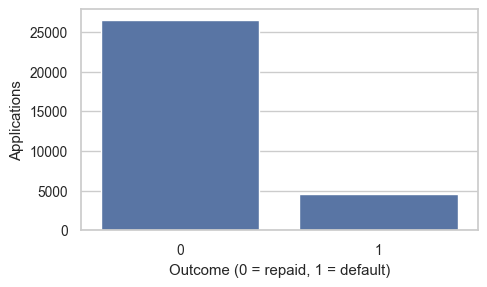

4,507 of 31,016 applications defaulted (14.53%). The majority class contains 26,509 repaid loans. Use stratified validation.

In [3]:
counts = data[target].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(data=data, x=target, ax=ax)
ax.set(xlabel="Outcome (0 = repaid, 1 = default)", ylabel="Applications")
save(fig, "outcomes")
note(f"{counts[1]:,} of {len(data):,} applications defaulted ({100 * data[target].mean():.2f}%). "
     f"The majority class contains {counts[0]:,} repaid loans. Use stratified validation.")

## Numerical distributions and outliers
Histograms use raw units and independent axes. Boxplots flag observations beyond 1.5 interquartile ranges. For discrete counts with many zeros the fences can coincide. A flag alone cannot establish an error. Recent payments are shown for audit only.

,count,mean,std,min,25%,50%,75%,max,skew,outside_IQR_fences
requested_amount,31016.0,11073.78,7348.22,500.00,5325.00,9762.50,15000.00,35000.00,1.07,873
interest_rate_pct,31016.0,11.96,3.70,5.42,8.94,11.83,14.46,24.59,0.29,39
monthly_emi,31016.0,322.69,207.97,16.25,166.04,278.48,426.46,1305.19,1.14,1056
annual_income,31016.0,68897.23,67180.19,4000.00,40000.00,59000.00,82000.00,6000000.00,33.16,1411
debt_to_income_ratio,31016.0,13.25,6.67,0.00,8.11,13.33,18.52,29.99,-0.02,0
delinquencies_24m,31016.0,0.15,0.49,0.00,0.00,0.00,0.00,11.00,5.00,3381
credit_inquiries_6m,31016.0,0.87,1.07,0.00,0.00,1.00,1.00,8.00,1.40,2826
active_credit_lines,31016.0,9.28,4.40,2.00,6.00,9.00,12.00,44.00,1.02,403
derogatory_public_records,31016.0,0.06,0.24,0.00,0.00,0.00,0.00,4.00,4.52,1670
revolving_credit_balance,31016.0,13263.31,15791.43,0.00,3655.75,8769.00,16899.00,149588.00,3.20,1935


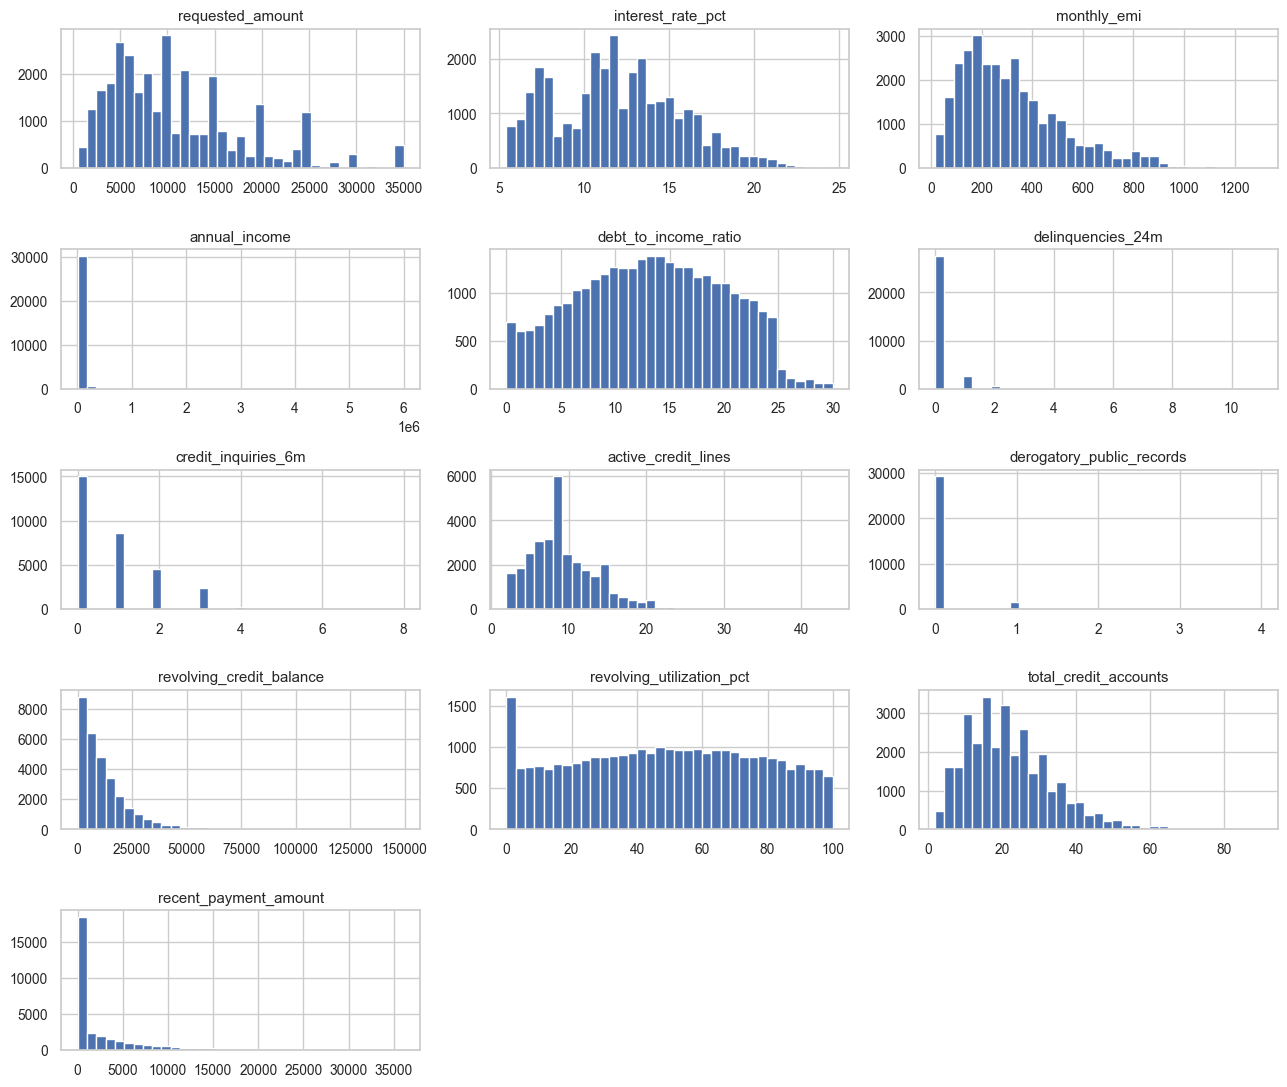

Annual income has a long right tail: median USD 59,000, maximum USD 6,000,000. The raw axis compresses typical incomes.

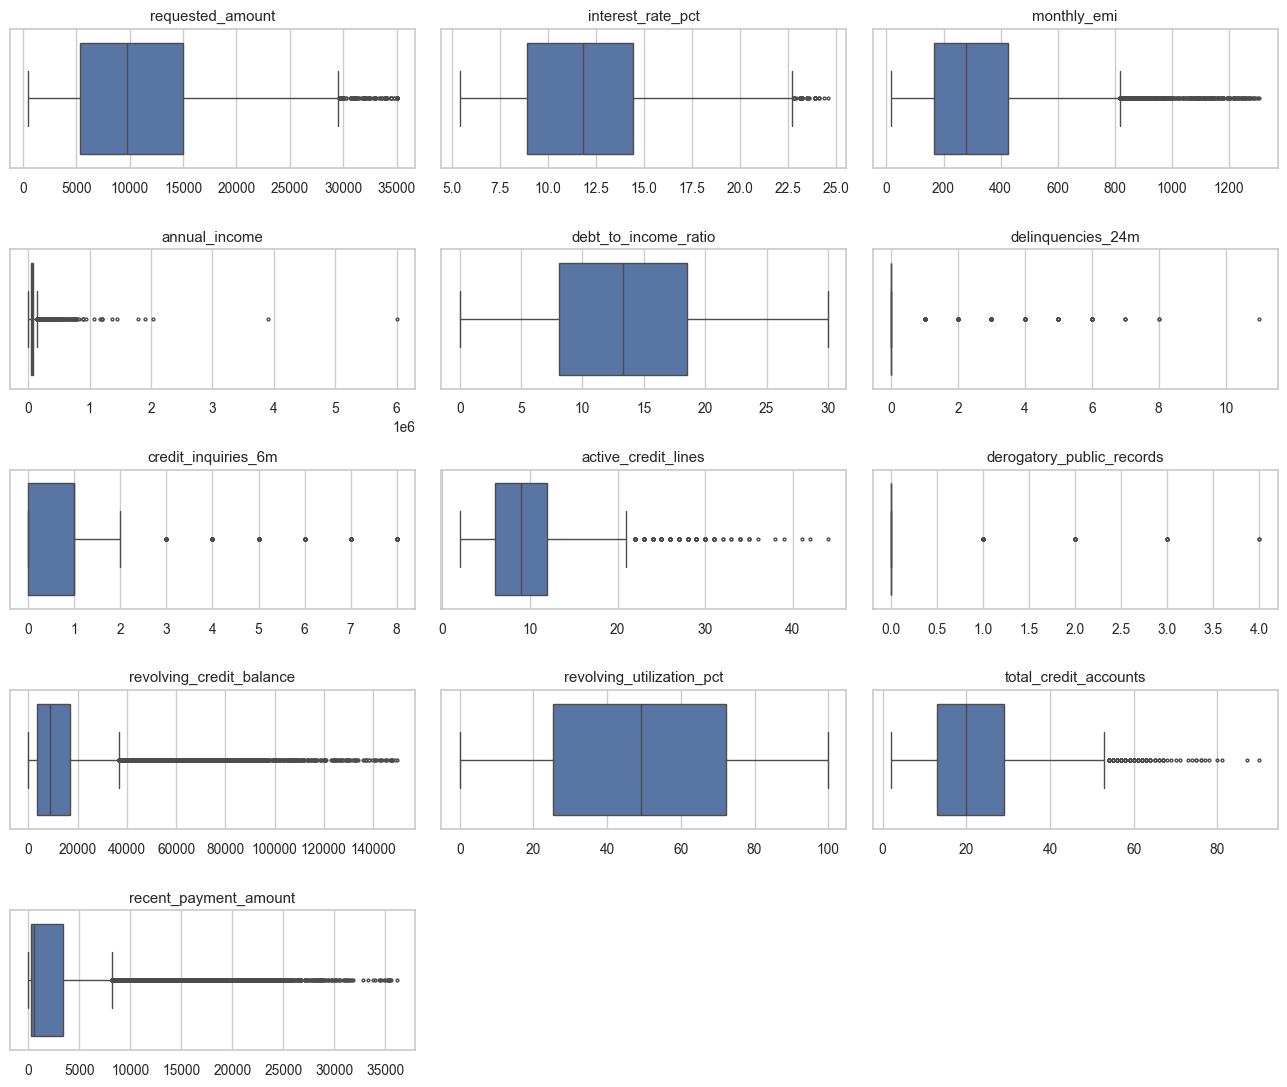

The income boxplot flags 1,411 observations. Keep all applications: the files provide no evidence for a universal error cutoff.

In [4]:
values = data[numbers]
summary = values.describe().T
summary["skew"] = values.skew()
lower, upper = values.quantile(0.25), values.quantile(0.75)
spread = upper - lower
summary["outside_IQR_fences"] = ((values < lower - 1.5 * spread) | (values > upper + 1.5 * spread)).sum()
display(summary.round(2))
for kind in ["histograms", "boxplots"]:
    fig, axes = plt.subplots((len(numbers)+2)//3, 3, figsize=(13, 11))
    for col, ax in zip(numbers, axes.flat):
        if kind == "histograms":
            ax.hist(data[col].dropna(), bins=35)
        else:
            sns.boxplot(x=data[col], ax=ax, fliersize=2)
        ax.set(title=col, xlabel="")
    for ax in list(axes.flat)[len(numbers):]:
        ax.remove()
    save(fig, kind)
    if kind == "histograms":
        note(f"Annual income has a long right tail: median USD {summary.loc['annual_income','50%']:,.0f}, "
             f"maximum USD {summary.loc['annual_income','max']:,.0f}. The raw axis compresses typical incomes.")
    else:
        note(f"The income boxplot flags {summary.loc['annual_income','outside_IQR_fences']:,} observations. "
             "Keep all applications: the files provide no evidence for a universal error cutoff.")

## Categorical distributions
Each bar counts applications, including missing employment. Inspect the tables for precise counts and percentages across all levels.

**repayment_tenure**

,applications,percent
repayment_tenure,,
36 months,23261,75.0
60 months,7755,25.0


**risk_tier**

,applications,percent
risk_tier,,
B,9310,30.02
A,8037,25.91
C,6345,20.46
D,4109,13.25
E,2170,7.00
F,800,2.58
G,245,0.79


**risk_subtier**

,applications,percent
risk_subtier,,
A4,2306,7.43
B3,2244,7.23
A5,2193,7.07
B5,2097,6.76
B4,1933,6.23
C1,1652,5.33
B2,1583,5.10
C2,1542,4.97
B1,1453,4.68


... (4 outputs left out)

**income_verification**

,applications,percent
income_verification,,
Not Verified,13428,43.29
Verified,9795,31.58
Source Verified,7793,25.13


**loan_purpose**

,applications,percent
loan_purpose,,
debt_consolidation,14562,46.95
credit_card,4049,13.05
other,3077,9.92
home_improvement,2333,7.52
major_purchase,1700,5.48
small_business,1434,4.62
car,1180,3.80
wedding,755,2.43
medical,543,1.75


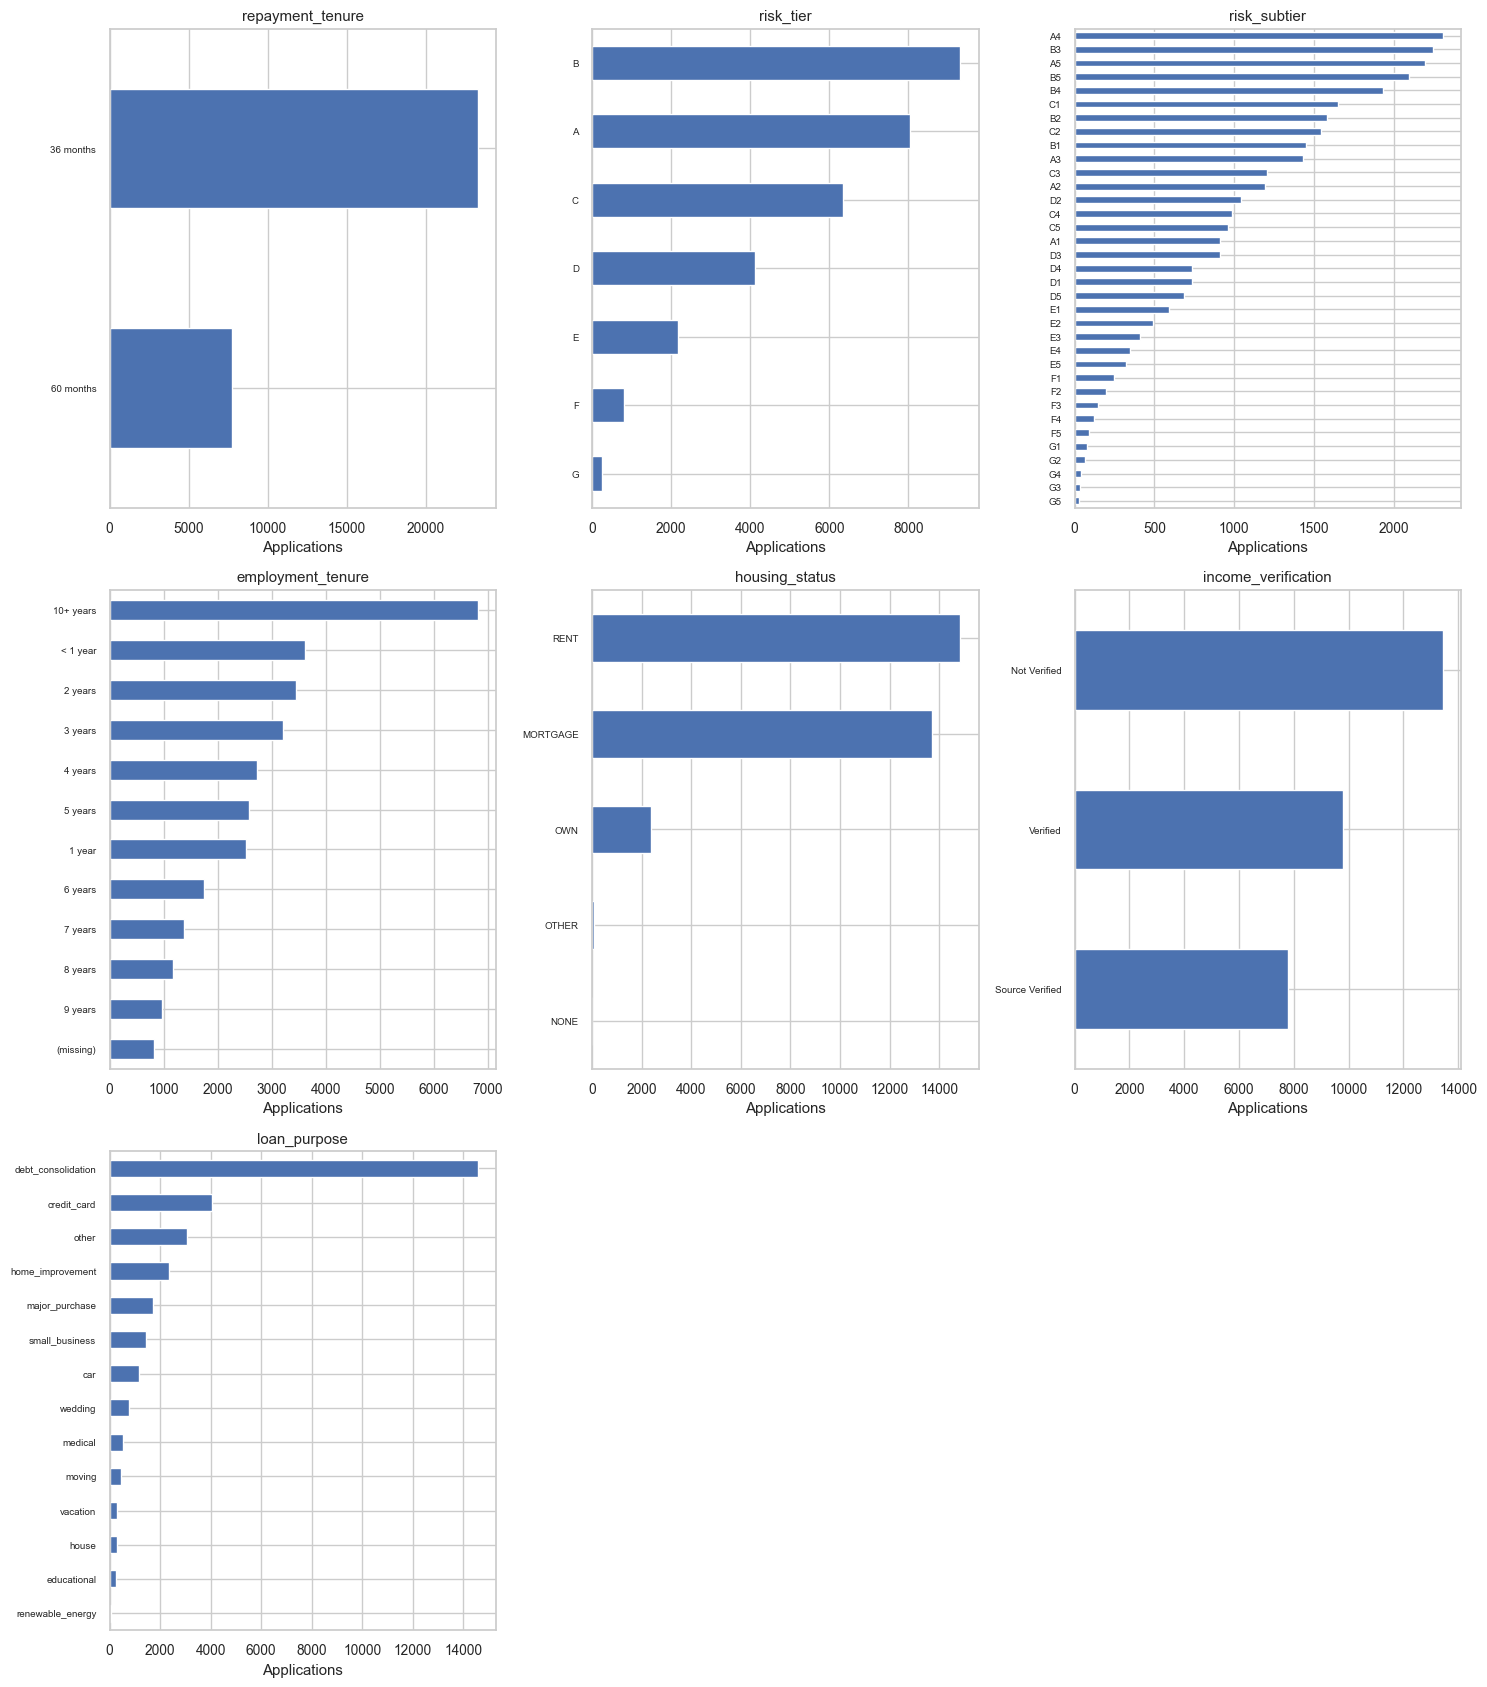

Most frequent levels by field: repayment_tenure = 36 months (75.0%), risk_tier = B (30.0%), risk_subtier = A4 (7.4%), employment_tenure = 10+ years (22.0%), housing_status = RENT (47.9%), income_verification = Not Verified (43.3%), loan_purpose = debt_consolidation (46.9%).

In [5]:
def category_counts(col):
    counts = data[col].fillna("(missing)").value_counts()
    return pd.DataFrame({"applications": counts, "percent": 100 * counts / len(data)})

fig, axes = plt.subplots(3, 3, figsize=(15, 17))
for col, ax in zip(categories, axes.flat):
    table = category_counts(col)
    display(Markdown(f"**{col}**"), table.round(2))
    table.applications.sort_values().plot.barh(ax=ax)
    ax.tick_params(axis="y", labelsize=7)
    ax.set(title=col, ylabel="", xlabel="Applications")
for ax in list(axes.flat)[len(categories):]:
    ax.remove()
save(fig, "category_counts")
note("Most frequent levels by field: " + ", ".join(
    f"{col} = {category_counts(col).index[0]} ({category_counts(col).percent.iloc[0]:.1f}%)"
    for col in categories) + ".")

## Correlations and redundancy
Pearson correlation measures linear association between numerical columns. Rank eligible pairs by absolute correlation and show pairs at or above 0.70. Identifiers and the outcome are omitted.

,,Pearson r
requested_amount,monthly_emi,0.931308


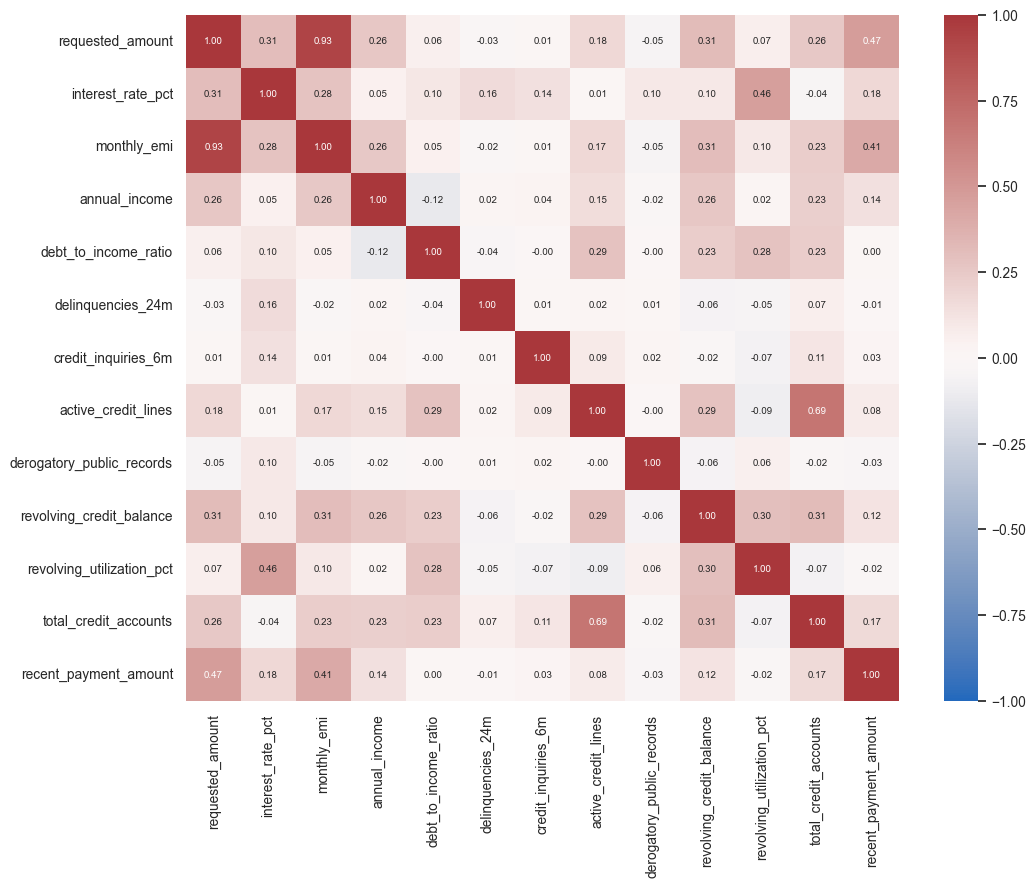

The strongest numerical pair is requested_amount and monthly_emi (r = 0.931). Requested principal and the scheduled installment capture overlapping loan size information.

In [6]:
corr = values.corr()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs = pairs.sort_values(key=abs, ascending=False)
display(pairs[pairs.abs() >= .70].rename("Pearson r").to_frame())
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7})
save(fig, "correlations")
a, b = pairs.index[0]
note(f"The strongest numerical pair is {a} and {b} (r = {pairs.iloc[0]:.3f}). "
     "Requested principal and the scheduled installment capture overlapping loan size information.")

## Default rates by application characteristic
For continuous measures, split the observed training values at quintiles. Compare credit counts as 0, 1, 2 and 3+. Keep missing values visible. Tables give the denominator alongside the percentage so rare groups can be interpreted cautiously.

**annual_income**

,applications,defaults,default_percent
annual_income,,,
"(3999.999, 37000.0]",6226,1157,18.58
"(37000.0, 50004.0]",6218,987,15.87
"(50004.0, 65382.0]",6166,891,14.45
"(65382.0, 90000.0]",6370,832,13.06
"(90000.0, 6000000.0]",6036,640,10.60


**requested_amount**

,applications,defaults,default_percent
requested_amount,,,
"(499.999, 5000.0]",7592,1054,13.88
"(5000.0, 7750.0]",4821,588,12.20
"(7750.0, 11250.0]",6202,827,13.33
"(11250.0, 16000.0]",6271,898,14.32
"(16000.0, 35000.0]",6130,1140,18.60


**interest_rate_pct**

,applications,defaults,default_percent
interest_rate_pct,,,
"(5.419, 7.9]",6415,344,5.36
"(7.9, 10.99]",6631,674,10.16
"(10.99, 12.86]",5566,829,14.89
"(12.86, 15.23]",6331,1086,17.15
"(15.23, 24.59]",6073,1574,25.92


**debt_to_income_ratio**

,applications,defaults,default_percent
debt_to_income_ratio,,,
"(-0.001, 6.88]",6205,754,12.15
"(6.88, 11.34]",6209,818,13.17
"(11.34, 15.28]",6208,929,14.96
"(15.28, 19.68]",6197,961,15.51
"(19.68, 29.99]",6197,1045,16.86


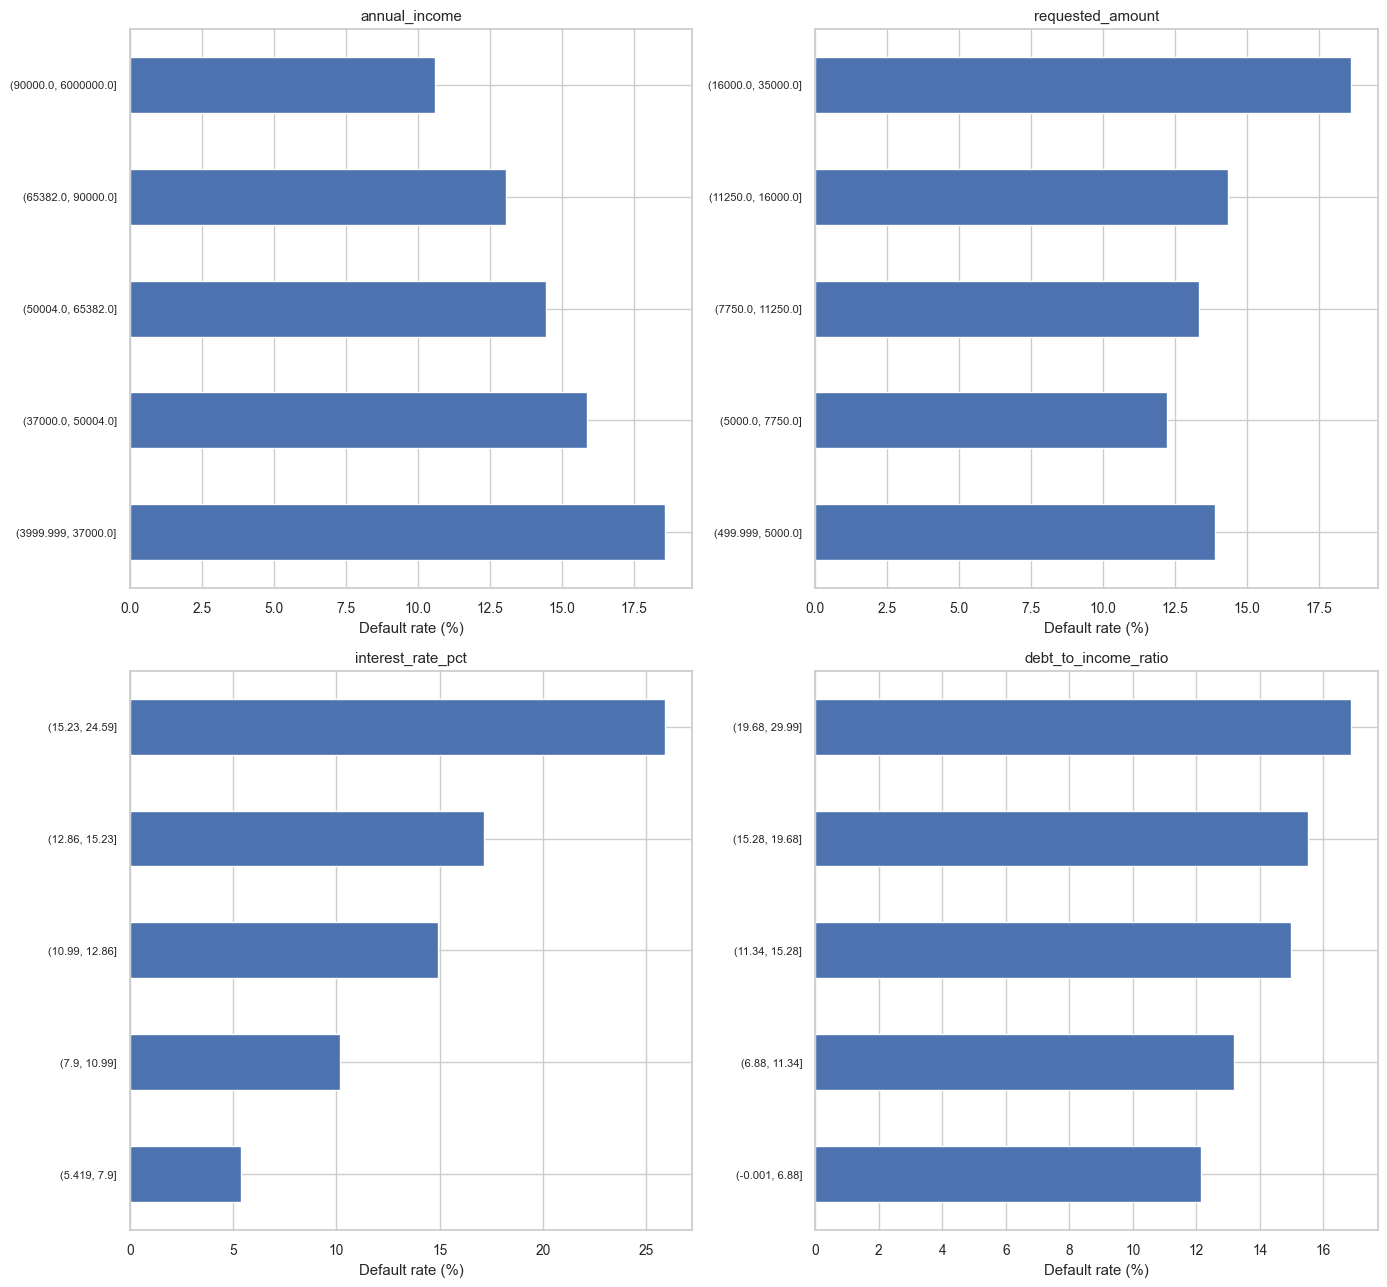

annual_income: observed rates range from 10.6% in (90000.0, 6000000.0] (n=6,036) to 18.6% in (3999.999, 37000.0] (n=6,226).

requested_amount: observed rates range from 12.2% in (5000.0, 7750.0] (n=4,821) to 18.6% in (16000.0, 35000.0] (n=6,130).

interest_rate_pct: observed rates range from 5.4% in (5.419, 7.9] (n=6,415) to 25.9% in (15.23, 24.59] (n=6,073).

debt_to_income_ratio: observed rates range from 12.2% in (-0.001, 6.88] (n=6,205) to 16.9% in (19.68, 29.99] (n=6,197).

**revolving_utilization_pct**

,applications,defaults,default_percent
revolving_utilization_pct,,,
"(-0.001, 19.9]",6211,605,9.74
"(19.9, 40.1]",6207,730,11.76
"(40.1, 58.118]",6169,898,14.56
"(58.118, 77.2]",6203,1034,16.67
"(77.2, 99.9]",6188,1227,19.83
(missing),38,13,34.21


... (2 outputs left out)

**credit_inquiries_6m**

,applications,defaults,default_percent
credit_inquiries_6m,,,
0,15028,1822,12.12
1,8609,1358,15.77
2,4553,756,16.60
3+,2826,571,20.21


**risk_tier**

,applications,defaults,default_percent
risk_tier,,,
A,8037,481,5.98
B,9310,1134,12.18
C,6345,1096,17.27
D,4109,894,21.76
E,2170,562,25.90
F,800,261,32.62
G,245,79,32.24


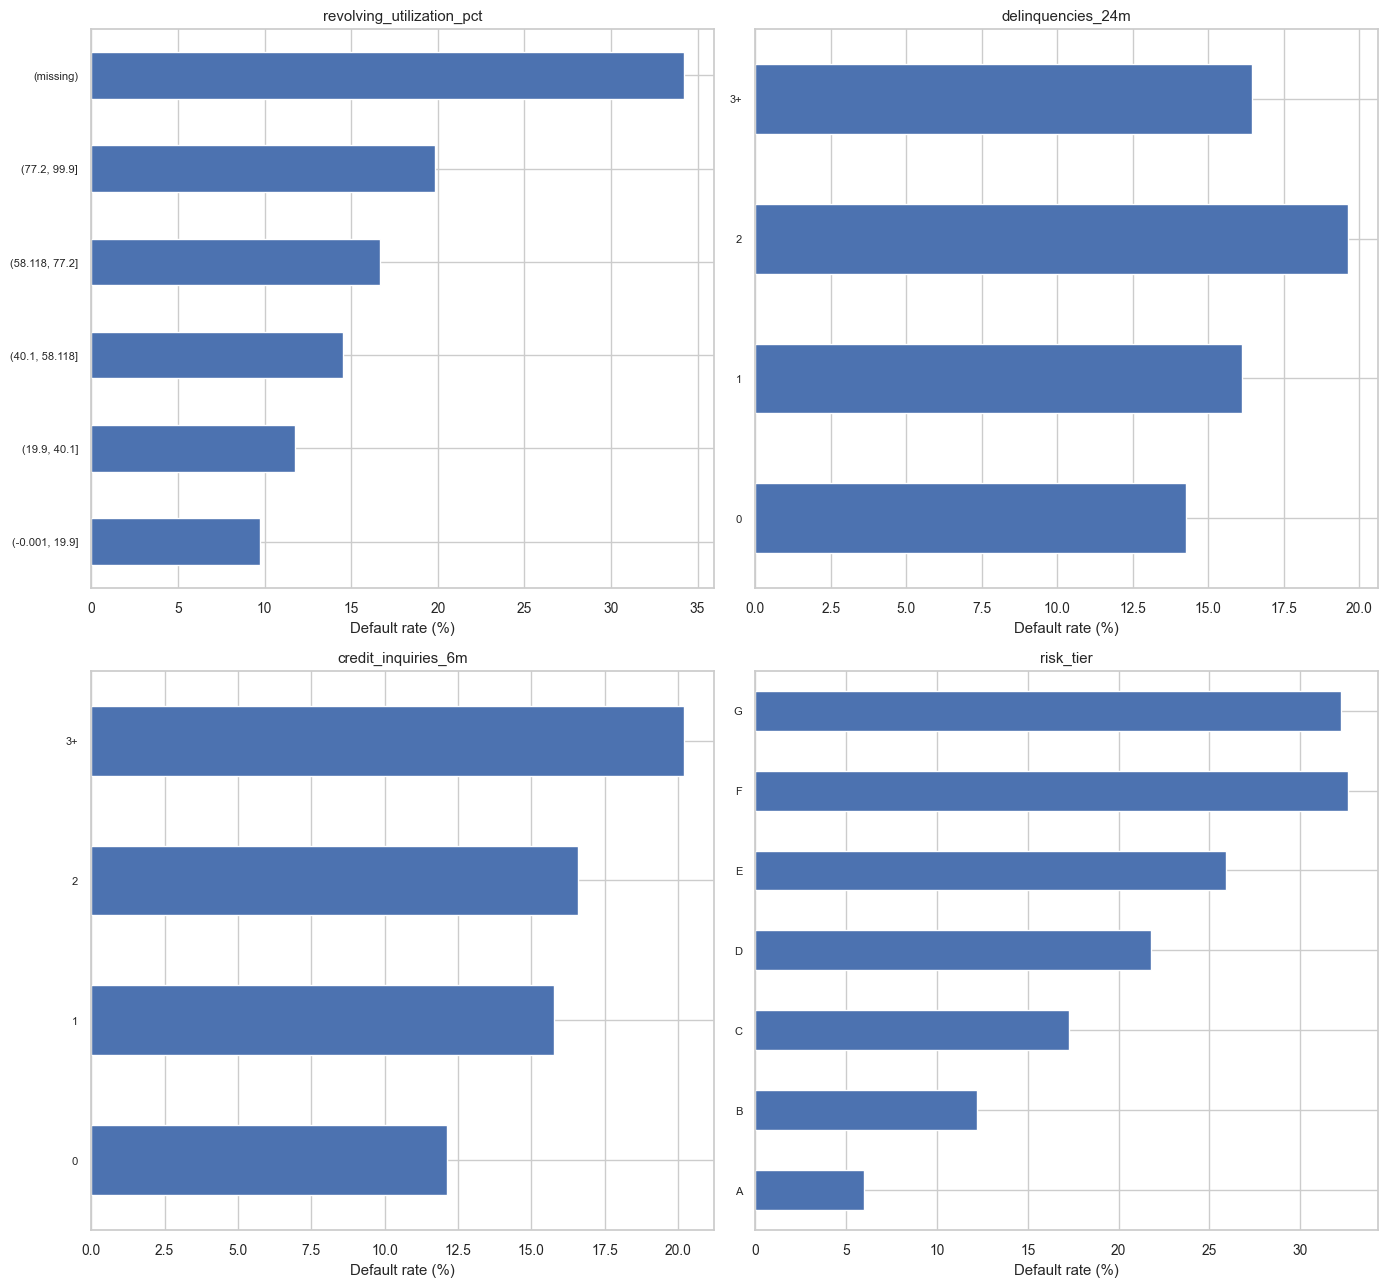

revolving_utilization_pct: observed rates range from 9.7% in (-0.001, 19.9] (n=6,211) to 34.2% in (missing) (n=38).

Across the five measured utilization groups, default rates rise from 9.7% to 19.8%. The missing group has only 38 applications.

delinquencies_24m: observed rates range from 14.3% in 0 (n=27,635) to 19.6% in 2 (n=540).

credit_inquiries_6m: observed rates range from 12.1% in 0 (n=15,028) to 20.2% in 3+ (n=2,826).

risk_tier: observed rates range from 6.0% in A (n=8,037) to 32.6% in F (n=800).

**risk_subtier**

... (3 outputs left out)

**housing_status**

,applications,defaults,default_percent
housing_status,,,
MORTGAGE,13712,1861,13.57
NONE,3,0,0.00
OTHER,82,13,15.85
OWN,2376,351,14.77
RENT,14843,2282,15.37


**loan_purpose**

,applications,defaults,default_percent
loan_purpose,,,
car,1180,130,11.02
credit_card,4049,450,11.11
debt_consolidation,14562,2213,15.20
educational,257,44,17.12
home_improvement,2333,271,11.62
house,295,46,15.59
major_purchase,1700,178,10.47
medical,543,85,15.65
moving,452,67,14.82


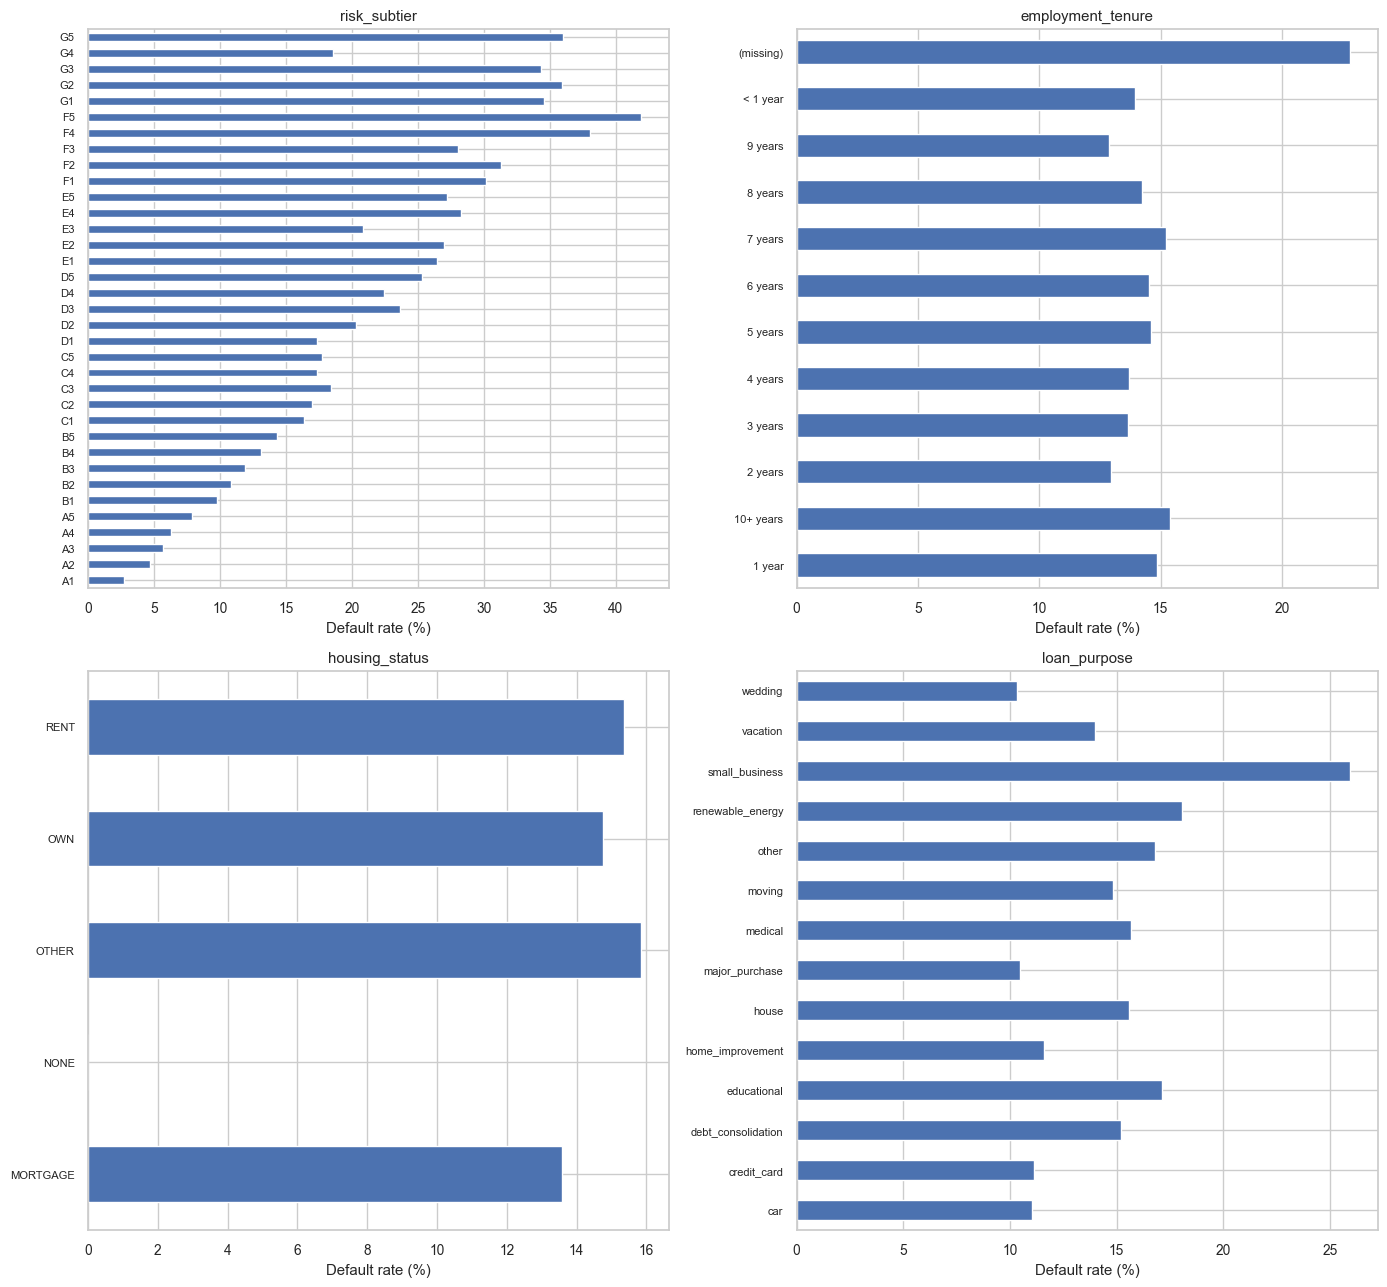

risk_subtier: observed rates range from 2.7% in A1 (n=912) to 41.9% in F5 (n=93).

employment_tenure: observed rates range from 12.9% in 9 years (n=978) to 22.8% in (missing) (n=829).

housing_status: observed rates range from 0.0% in NONE (n=3) to 15.9% in OTHER (n=82).

The two largest housing groups, RENT and MORTGAGE, have default rates of 15.4% and 13.6%. The three NONE applications are too few to estimate a reliable group rate.

loan_purpose: observed rates range from 10.3% in wedding (n=755) to 25.9% in small_business (n=1,434).

In [7]:
continuous = ["annual_income", "requested_amount", "interest_rate_pct", "debt_to_income_ratio",
              "revolving_utilization_pct"]
discrete = ["delinquencies_24m", "credit_inquiries_6m"]
relationship_fields = continuous + discrete + ["risk_tier", "risk_subtier", "employment_tenure",
                                                "housing_status", "loan_purpose"]

def grouped_rates(col):
    group = data[col]
    if col in continuous:
        group = pd.qcut(group, 5, duplicates="drop")
    elif col in discrete:
        group = pd.cut(group, [-np.inf, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])
    group = group.astype("category")
    group = group.cat.add_categories("(missing)").fillna("(missing)")
    table = data[target].groupby(group, observed=True).agg(["size", "sum", "mean"])
    table.columns = ["applications", "defaults", "default_percent"]
    table.default_percent *= 100
    return table

for page in range(3):
    fig, axes = plt.subplots(2, 2, figsize=(14, 13))
    messages = []
    for col, ax in zip(relationship_fields[page*4:page*4+4], axes.flat):
        table = grouped_rates(col)
        display(Markdown(f"**{col}**"), table.round(2))
        table.default_percent.plot.barh(ax=ax)
        ax.set(title=col, ylabel="", xlabel="Default rate (%)")
        ax.tick_params(axis="y", labelsize=8)
        low, high = table.default_percent.idxmin(), table.default_percent.idxmax()
        messages.append(f"{col}: observed rates range from {table.loc[low,'default_percent']:.1f}% "
                        f"in {low} (n={table.loc[low,'applications']:,}) to "
                        f"{table.loc[high,'default_percent']:.1f}% in {high} "
                        f"(n={table.loc[high,'applications']:,}).")
        if col == "revolving_utilization_pct":
            observed = table.drop(index="(missing)")
            messages.append(f"Across the five measured utilization groups, default rates rise "
                            f"from {observed.default_percent.iloc[0]:.1f}% to "
                            f"{observed.default_percent.iloc[-1]:.1f}%. The missing group has "
                            f"only {table.loc['(missing)', 'applications']} applications.")
        if col == "housing_status":
            messages.append(f"The two largest housing groups, RENT and MORTGAGE, have default "
                            f"rates of {table.loc['RENT','default_percent']:.1f}% and "
                            f"{table.loc['MORTGAGE','default_percent']:.1f}%. The three NONE "
                            "applications are too few to estimate a reliable group rate.")
    save(fig, f"default_rates_{page+1}")
    for message in messages:
        note(message)

## Interpretation and export
Risk grades and pricing may summarize information already present in the application. Differences between groups can reflect that overlap. Report the observations with their sample sizes.

In [8]:
note("The assignment describes recent_payment_amount as a payment received on the account. "
     "Its availability at submission is unverified. Exclude it from prediction. "
     "The charts summarize historical associations, and estimates in small groups are unstable.")
(reports / "eda_findings.md").write_text(
    "# FinBridge training data findings\n\n" + "\n\n".join(findings) + "\n", encoding="utf-8")

The assignment describes recent_payment_amount as a payment received on the account. Its availability at submission is unverified. Exclude it from prediction. The charts summarize historical associations, and estimates in small groups are unstable.

2842